In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
# Load the dataset
df = pd.read_json('rossmann_store_sales.json')
df.head()


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [3]:
# Check the structure of the dataset
df.info()
df.shape

<class 'pandas.DataFrame'>
Index: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype         
---  ------                     --------------    -----         
 0   Store                      1017209 non-null  int64         
 1   DayOfWeek                  1017209 non-null  int64         
 2   Date                       1017209 non-null  datetime64[us]
 3   Sales                      1017209 non-null  int64         
 4   Customers                  1017209 non-null  int64         
 5   Open                       1017209 non-null  int64         
 6   Promo                      1017209 non-null  int64         
 7   StateHoliday               1017209 non-null  object        
 8   SchoolHoliday              1017209 non-null  int64         
 9   StoreType                  1017209 non-null  str           
 10  Assortment                 1017209 non-null  str           
 11  CompetitionDistance        1014567 non-null  float64 

(1017209, 18)

In [4]:
# Check for missing values
print(df.isnull().sum())

Store                             0
DayOfWeek                         0
Date                              0
Sales                             0
Customers                         0
Open                              0
Promo                             0
StateHoliday                      0
SchoolHoliday                     0
StoreType                         0
Assortment                        0
CompetitionDistance            2642
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
Promo2                            0
Promo2SinceWeek              508031
Promo2SinceYear              508031
PromoInterval                508031
dtype: int64


In [5]:
# Remove Closed Stores because they do not contribute to sales prediction
df = df[df['Open'] == 1]


In [6]:
# Handle missing values

# Competition distance - fill with median
df['CompetitionDistance'] = df['CompetitionDistance'].fillna(
    df['CompetitionDistance'].median()
)

# Competition open date - fill with 0 (indicating no competition)
df['CompetitionOpenSinceMonth'] = df['CompetitionOpenSinceMonth'].fillna(0)
df['CompetitionOpenSinceYear'] = df['CompetitionOpenSinceYear'].fillna(0)

# Promo2 information - fill with 0 (indicating no promotion)
df['Promo2SinceWeek'] = df['Promo2SinceWeek'].fillna(0)
df['Promo2SinceYear'] = df['Promo2SinceYear'].fillna(0)

# Promo interval - fill with 'None' (indicating no promotion)
df['PromoInterval'] = df['PromoInterval'].fillna('None')

In [7]:
# Check for missing values again after handling
print(df.isnull().sum())

Store                        0
DayOfWeek                    0
Date                         0
Sales                        0
Customers                    0
Open                         0
Promo                        0
StateHoliday                 0
SchoolHoliday                0
StoreType                    0
Assortment                   0
CompetitionDistance          0
CompetitionOpenSinceMonth    0
CompetitionOpenSinceYear     0
Promo2                       0
Promo2SinceWeek              0
Promo2SinceYear              0
PromoInterval                0
dtype: int64


In [8]:
# Convert data types
df['CompetitionOpenSinceMonth'] = df['CompetitionOpenSinceMonth'].astype(int)
df['CompetitionOpenSinceYear'] = df['CompetitionOpenSinceYear'].astype(int)

df['Promo2SinceWeek'] = df['Promo2SinceWeek'].astype(int)
df['Promo2SinceYear'] = df['Promo2SinceYear'].astype(int)

df['Date'] = pd.to_datetime(df['Date'])

In [9]:
# Check for duplicated rows
print(df.duplicated().sum())

0


In [10]:
#Check for data types
print(df.dtypes)

Store                                 int64
DayOfWeek                             int64
Date                         datetime64[us]
Sales                                 int64
Customers                             int64
Open                                  int64
Promo                                 int64
StateHoliday                         object
SchoolHoliday                         int64
StoreType                               str
Assortment                              str
CompetitionDistance                 float64
CompetitionOpenSinceMonth             int64
CompetitionOpenSinceYear              int64
Promo2                                int64
Promo2SinceWeek                       int64
Promo2SinceYear                       int64
PromoInterval                           str
dtype: object


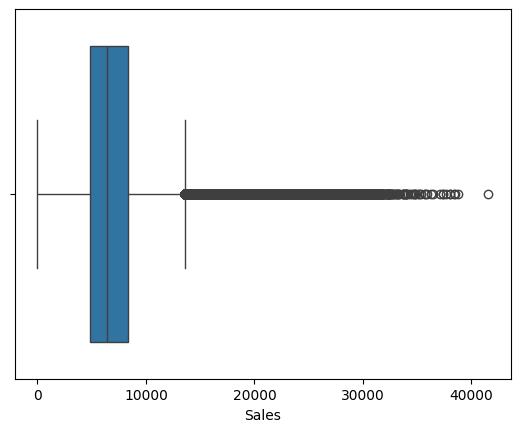

In [11]:
# Visualize the distribution of sales to identify outliers
sns.boxplot(x=df['Sales'])
plt.show()

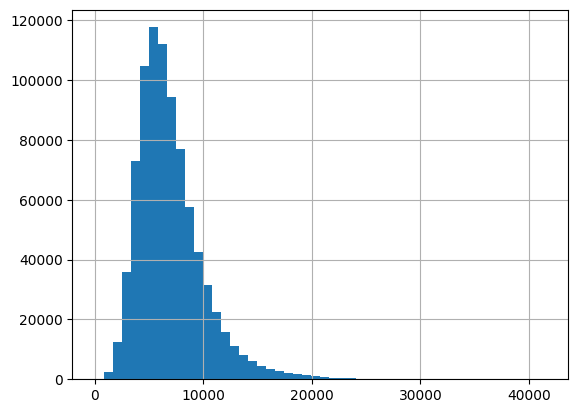

In [12]:
df['Sales'].hist(bins=50)
plt.show()

In [13]:
Q1 = df['Sales'].quantile(0.25)
Q3 = df['Sales'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['Sales'] < lower) | (df['Sales'] > upper)]

print(outliers.shape)

(30769, 18)


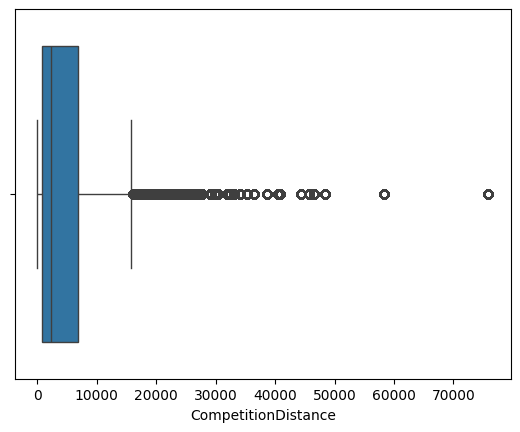

In [14]:
# Visualize the distribution of competition distance to identify outliers
sns.boxplot(x=df['CompetitionDistance'])
plt.show()

# Feature Engineering 

In [15]:
# Extract date features
df = df.sort_values(['Store','Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)

In [16]:
# Lag features to capture temporal dependencies in sales
df['Sales_Lag_7'] = df['Sales'].shift(7)
df['Sales_Lag_14'] = df['Sales'].shift(14)
df['Sales_Lag_30'] = df['Sales'].shift(30)

In [17]:
# Rolling averages for smoothing sales trends
df['RollingMean_7'] = df['Sales'].shift(1).rolling(7).mean()
df['RollingMean_30'] = df['Sales'].shift(1).rolling(30).mean()

In [18]:
# Competition duration 
df['CompetitionOpenDuration'] = (
    (df['Year'] - df['CompetitionOpenSinceYear']) * 12
    + (df['Month'] - df['CompetitionOpenSinceMonth'])
)

# Replace negative values
df['CompetitionOpenDuration'] = df['CompetitionOpenDuration'].clip(lower=0)

In [19]:
# Promo duration
df['PromoDuration'] = (
    (df['Year'] - df['Promo2SinceYear']) * 52
    + (df['WeekOfYear'] - df['Promo2SinceWeek'])
)

# Replace negative values
df['PromoDuration'] = df['PromoDuration'].clip(lower=0)

In [20]:
df['CompetitionDistance_Log'] = np.log1p(df['CompetitionDistance'])

In [21]:
from sklearn.preprocessing import LabelEncoder

categorical_cols = [
    'StateHoliday',
    'StoreType',
    'Assortment',
    'PromoInterval'
]

le = LabelEncoder()

for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))

# Remove rows with zero sales as they do not contribute to the prediction
df = df[df['Sales'] > 0]

df = df.dropna()

In [22]:
df = df.drop(columns=[
    'Store',                            # Store ID is not needed for prediction
    'Customers',                        # Customer count is not known at prediction time
    'Date',                             # Date is not needed as we have extracted date features
    'CompetitionDistance',              # Competition distance is not needed as we have created a log-transformed version
    'CompetitionOpenSinceMonth',        # Competition open month is not needed as we have created a competition duration feature            
    'CompetitionOpenSinceYear',
    'Promo2SinceWeek',                  # Promo2 open week is not needed as we have created a promo duration feature
    'Promo2SinceYear'
])

In [23]:
# Save the cleaned dataset to a new JSON file
df.to_json(
    "cleaned_rossmann.json",
    orient='records',
    indent=4
)

# **Model Selection**

# 1. LightGBM


In [24]:
# Define features and target variable
X = df.drop('Sales', axis=1)
y = df['Sales']

In [25]:
# Split the data into training and testing sets
split_index = int(len(df) * 0.8)

train = df.iloc[:split_index]
test = df.iloc[split_index:]

X_train = train.drop(['Sales'], axis=1)
y_train = train['Sales']

X_test = test.drop(['Sales'], axis=1)
y_test = test['Sales']

In [26]:
from lightgbm import LGBMRegressor

model = LGBMRegressor(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=10,
    random_state=42
)

model.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.017721 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2163
[LightGBM] [Info] Number of data points in the train set: 675446, number of used features: 20
[LightGBM] [Info] Start training from score 6969.558807


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,10
,learning_rate,0.05
,n_estimators,2000
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [27]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

In [28]:
y_pred = model.predict(X_test)

In [29]:
print(X_train.columns)

Index(['DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday',
       'StoreType', 'Assortment', 'Promo2', 'PromoInterval', 'Year', 'Month',
       'Day', 'WeekOfYear', 'Sales_Lag_7', 'Sales_Lag_14', 'Sales_Lag_30',
       'RollingMean_7', 'RollingMean_30', 'CompetitionOpenDuration',
       'PromoDuration', 'CompetitionDistance_Log'],
      dtype='str')


In [30]:
# Evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

mape = mean_absolute_percentage_error(y_test, y_pred) * 100

# Mean sales
mean_sales = y_test.mean()

# RMSE relative to mean sales
rmse_percentage = (rmse / mean_sales) * 100

# Print results
print("===== Model Evaluation =====")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"Mean Sales : {mean_sales:.2f}")
print(f"RMSE Percentage of Mean Sales : {rmse_percentage:.2f}%")

===== Model Evaluation =====
MAE  : 642.51
RMSE : 943.65
MAPE : 10.27%
Mean Sales : 6901.89
RMSE Percentage of Mean Sales : 13.67%


# 2. XGBoost

In [31]:
from xgboost import XGBRegressor    

In [32]:
xgb_model = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=10,
    random_state=42
)

In [33]:
xgb_model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes

In [34]:
y_pred_xgb = xgb_model.predict(X_test)

In [35]:
# Metrics
mae = mean_absolute_error(y_test, y_pred_xgb)

rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

mape = mean_absolute_percentage_error(y_test, y_pred_xgb) * 100

mean_sales = y_test.mean()

rmse_percentage = (rmse / mean_sales) * 100

# Print
print("===== XGBoost Evaluation =====")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"Mean Sales : {mean_sales:.2f}")
print(f"RMSE Percentage of Mean Sales : {rmse_percentage:.2f}%")

===== XGBoost Evaluation =====
MAE  : 631.58
RMSE : 931.30
MAPE : 10.17%
Mean Sales : 6901.89
RMSE Percentage of Mean Sales : 13.49%


# 3. Random Forest

In [36]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

In [38]:
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",2000
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples

In [39]:
y_pred_rf = rf_model.predict(X_test)

In [40]:
# Metrics
mae = mean_absolute_error(y_test, y_pred_rf)

rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))

mape = mean_absolute_percentage_error(y_test, y_pred_rf) * 100

mean_sales = y_test.mean()

rmse_percentage = (rmse / mean_sales) * 100

# Print
print("===== Random Forest Evaluation =====")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"Mean Sales : {mean_sales:.2f}")
print(f"RMSE Percentage of Mean Sales : {rmse_percentage:.2f}%")

===== Random Forest Evaluation =====
MAE  : 721.38
RMSE : 1041.69
MAPE : 11.66%
Mean Sales : 6901.89
RMSE Percentage of Mean Sales : 15.09%


# 4. LSTM

In [41]:
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

In [42]:
feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

X_train_scaled = feature_scaler.fit_transform(X_train)
X_test_scaled = feature_scaler.transform(X_test)

y_train_scaled = target_scaler.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled = target_scaler.transform(y_test.values.reshape(-1, 1))

In [43]:
X_train_lstm = X_train_scaled.reshape((X_train_scaled.shape[0], 1, X_train_scaled.shape[1]))
X_test_lstm = X_test_scaled.reshape((X_test_scaled.shape[0], 1, X_test_scaled.shape[1]))

In [44]:
lstm_model = Sequential()

lstm_model.add(LSTM(64, activation='relu', input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])))
lstm_model.add(Dropout(0.2))
lstm_model.add(Dense(32, activation='relu'))
lstm_model.add(Dense(1))

lstm_model.compile(optimizer='adam', loss='mse')

c:\Users\zakwa\OneDrive\Documents\DEG\DEG SEM2 3RD YEAR\fyp\FYP - CODE\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [45]:
history = lstm_model.fit(
    X_train_lstm,
    y_train_scaled,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 44s 2ms/step - loss: 0.0013 - val_loss: 0.0014
Epoch 2/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 110s 7ms/step - loss: 0.0011 - val_loss: 0.0013
Epoch 3/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 74s 3ms/step - loss: 0.0010 - val_loss: 0.0011
Epoch 4/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 50s 3ms/step - loss: 9.6141e-04 - val_loss: 0.0010
Epoch 5/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 44s 3ms/step - loss: 9.2658e-04 - val_loss: 0.0012
Epoch 6/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 43s 3ms/step - loss: 9.0678e-04 - val_loss: 9.7448e-04
Epoch 7/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 44s 3ms/step - loss: 8.9004e-04 - val_loss: 0.0011
Epoch 8/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 38s 2ms/step - loss: 8.7823e-04 - val_loss: 0.0010
Epoch 9/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 44s 3ms/step - loss: 8.6581e-04 - val_loss: 0.0010
Epoch 10/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 42s 2ms/step - loss: 8.5553e-04 - val_loss: 0.0011
Epoch 11/20
16887/16887 ━━━━━━━━━━━━━━━━━━━━ 44s 3ms/ste

In [46]:
y_pred_lstm_scaled = lstm_model.predict(X_test_lstm)

y_pred_lstm = target_scaler.inverse_transform(y_pred_lstm_scaled).flatten()

5277/5277 ━━━━━━━━━━━━━━━━━━━━ 19s 3ms/step


In [47]:
mae = mean_absolute_error(y_test, y_pred_lstm)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lstm))
mape = mean_absolute_percentage_error(y_test, y_pred_lstm) * 100

mean_sales = y_test.mean()
rmse_percentage = (rmse / mean_sales) * 100

print("===== LSTM Evaluation =====")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"Mean Sales : {mean_sales:.2f}")
print(f"RMSE Percentage of Mean Sales : {rmse_percentage:.2f}%")

===== LSTM Evaluation =====
MAE  : 780.51
RMSE : 1114.05
MAPE : 12.50%
Mean Sales : 6901.89
RMSE Percentage of Mean Sales : 16.14%
